# Week 12: ML Review

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py
!wget -qO- "https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/lfw.tar.gz" | tar xz

In [2]:
from random import randrange

from sklearn.metrics import classification_report, confusion_matrix

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from data_utils import LFWUtils
from data_utils import classification_error, display_confusion_matrix
from image_utils import make_image

## Face Unlock

Let's train a model to detect our face. We can think of this as a simpler version of one of the components inside something like the face ID software on our phones.

We'll skip the face detection part, which is when we find faces in an image, and assume we can get cropped and aligned faces out of images or video streams. We'll look at face detection later in the semester.

This is a slightly different kind of problem from the classification exercise we did in class, but the process is mostly the same.

We will use a dataset with other people's faces, but in the end we are only interested on how well our model detects our face.

### We Always Start with the Data

The dataset we're using is inside `./data/images/lfw/cropped`. It's a subset of the [Labeled Faces in the Wild](https://vis-www.cs.umass.edu/lfw/) dataset.

Take a look at the directory.

What's there?

How's the data organized and labeled?

### Loading the Data

Since we're not interested in generic classification, and measuring how we do on unlabeled data, this whole dataset is labeled, and we can read it into `train` and `test` subsets by calling the `train_test_split()` function of the `LFWUtils` class.

This function takes an optional parameter that specifies what portion of the data should be used for the `test` dataset. We can start with the default value of $0.5$.

In [3]:
train, test = LFWUtils.train_test_split(dir="./data/image/lfw/cropped", test_pct=0.5)

### Looking at the Data

Ok. Data is loaded.

What's in the data? How is it actually organized?

Take a look at the objects that were returned in each of the $2$ variables.

How big are our datasets?

Take a look at the `LABELS` and `L2I` members of the `LFWUtils` class (`LFWUtils.LABELS` and `LFWUtils.L2I`).

In [4]:
# TODO: look at dataset objects (train and test variables). What's in them?
print("Type of train:", type(train))
print("Type of test:", type(test))

# If these are tuples (for example pixels and labels), show what each part is
if isinstance(train, tuple):
    print("Number of parts in train:", len(train))
    for part_index in range(len(train)):
        part = train[part_index]
        print("Part", part_index, "type:", type(part))

# TODO: how big are they? (how many records?)
if isinstance(train, tuple):
    num_train_records = len(train[0])
    num_test_records = len(test[0])
else:
    num_train_records = len(train)
    num_test_records = len(test)

print("Train records:", num_train_records)
print("Test records:", num_test_records)

# TODO: how many labels do they have?
all_labels = LFWUtils.LABELS
num_labels = len(all_labels)
print("Number of labels:", num_labels)

# TODO: what are the labels
print("Labels:", all_labels)
print("Label to index:", LFWUtils.L2I)

Type of train: <class 'dict'>
Type of test: <class 'dict'>
Train records: 3
Test records: 3
Number of labels: 26
Labels: ['annan', 'arroyo', 'berlusconi', 'blair', 'bushgw', 'bushl', 'chavez', 'clintonb', 'erdogan', 'fox', 'giuliani', 'jolie', 'koizumi', 'lopez', 'lula', 'mauresmo', 'mk', 'moohyun', 'powell', 'putin', 'ryder', 'schwarzenegger', 'sukarnoputri', 'watts', 'williams', 'woods']
Label to index: {'annan': 0, 'arroyo': 1, 'berlusconi': 2, 'blair': 3, 'bushgw': 4, 'bushl': 5, 'chavez': 6, 'clintonb': 7, 'erdogan': 8, 'fox': 9, 'giuliani': 10, 'jolie': 11, 'koizumi': 12, 'lopez': 13, 'lula': 14, 'mauresmo': 15, 'mk': 16, 'moohyun': 17, 'powell': 18, 'putin': 19, 'ryder': 20, 'schwarzenegger': 21, 'sukarnoputri': 22, 'watts': 23, 'williams': 24, 'woods': 25}


### Visualizing the Data

We can open some random images to make sure the content of our datasets make sense.

Our `LFWUtils` class has some member variables that hold the image dimensions (`LFWUtils.IMAGE_SIZE`, `LFWUtils.IMAGE_WIDTH`, `LFWUtils.IMAGE_HEIGHT`)

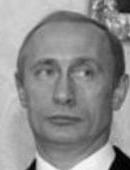

id: 19 
label: putin 
from: putin-012.jpg


In [5]:
train_size = len(train["labels"])
ridx = randrange(0, train_size)

label_id = train["labels"][ridx]

display(make_image(train["pixels"][ridx], width=LFWUtils.IMAGE_SIZE[0]))

print("id:", label_id,
      "\nlabel:", LFWUtils.LABELS[label_id],
      "\nfrom:", train["files"][ridx])

### Adding your images

Create a directory in the `dataset` directory for your images. Give it a one-word name, like your last name, your New School id or your initials. For example, mine is called `tgh` and is located at: `./data/images/lfw/cropped/tgh`.

Now, add between $20$ and $30$ images of your face to your directory. 

The images should be just like the ones that are already there for the other people:
- $130$ pixels wide
- $170$ pixels tall
- single-channel grayscale
- jpeg format
- named `label-number.jpg` (for example: `tgh-000.jpg`)

Feel free to do this manually using Photoshop or any other image editing software, but the easiest way is to use this interface that automatically crops faces out of pictures and creates images in the correct format:

### [Face Align](https://huggingface.co/spaces/visualizedata/PSAM5020-FaceAlign-Gradio)

It will also align the faces and put the eyes in a consistent location. There's even an option to capture pictures from a live camera stream.

### Reload Dataset

Just run the `train_test_split()` again.

### PCA, Classification, etc etc etc

Now that we have added our images to the dataset, let's train a classifier and see how well it performs on not just classification, but on recognizing our face.

The images are $130$ x $170$ ($22\text{,}100$ pixels), so let's do `PCA`. We can aim for an explained variance value of about $80\%$, and adjust that later if we find necessary.

Once we have the PCs for our training dataset in a `DataFrame` we can add a `label` column to it with the correct labels we have in `train["labels"]`.

We can also create a `DataFrame` for testing now by using the same `PCA` object to `transform()` the `test["pixels"]` data.

Since we won't train anything with the test dataset, it's ok to just keep the labels in `test["labels"]` as they are.

In [6]:
import pandas as pd

# TODO: create PCA, fit and transform train data
face_pca = PCA(n_components=0.8)
train_pca_features = face_pca.fit_transform(train["pixels"])

# TODO: check PCA captured variance
num_components = face_pca.n_components_
total_variance = face_pca.explained_variance_ratio_.sum()
print("Components kept:", num_components)
print("Variance captured:", total_variance)

# TODO: prepare DataFrame for training (add label column)
column_names = []
for index in range(num_components):
    column_name = "pc" + str(index)
    column_names.append(column_name)

train_df = pd.DataFrame(train_pca_features, columns=column_names)
train_df["label"] = train["labels"]
display(train_df.head(5))

# TODO: create the test DataFrame by running PCA on the test data
test_pca_features = face_pca.transform(test["pixels"])
test_df = pd.DataFrame(test_pca_features, columns=column_names)
test_df["label"] = test["labels"]
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Components kept: 30
Variance captured: 0.8018643656629579


,pc0,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,...,pc21,pc22,pc23,pc24,pc25,pc26,pc27,pc28,pc29,label
0,-1580.762392,-2968.502740,-4149.922911,-591.802646,-1042.513524,84.894913,1248.183718,1697.874229,1715.809324,816.695350,...,1230.636541,261.273524,176.969203,-872.618109,-466.163640,-298.452016,21.593956,567.902194,-254.244856,0
1,4434.082918,-290.441325,-5152.624006,237.960800,168.327533,-295.103868,1420.718642,362.730398,125.474373,-496.565207,...,172.192490,-519.704127,80.091569,-166.278893,416.102959,665.676248,-700.252678,59.649346,-26.310037,0
2,1805.477260,-4505.134080,-1413.909585,-1098.074551,328.955460,-665.768882,-690.826750,-377.073810,-921.449409,687.452757,...,465.008515,109.582549,-664.245897,-710.508827,-156.003925,-1.802387,-1016.725860,457.286306,-8.859368,0
3,-933.447352,974.316237,-7796.157740,-234.479570,248.185139,-1184.565843,96.180887,-811.756820,2639.353129,-668.739420,...,-774.078042,1094.414374,-840.644080,626.515482,12.813721,710.309538,-633.401912,854.909531,481.793065,0
4,-877.703364,822.807193,-3862.479367,-3796.166236,1507.048374,-724.544969,2245.869070,-2047.001811,1724.867956,1158.215353,...,-803.461494,93.034909,-164.497356,322.928634,-1192.836779,-925.405581,-213.226004,189.831430,109.963552,0


Train shape: (456, 31)
Test shape: (448, 31)


We can use the following cell to take a look at our images and their reconstructions.

This assumes the `DataFrame` is called `train_df` and the `PCA` object is called `face_pca`. Adjust these if necessary.

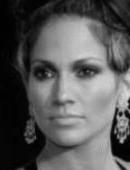

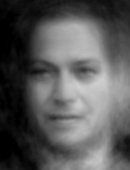

In [7]:
train_size = len(train["labels"])
ridx = randrange(0, train_size)

# reconstruct image
pca_pixels = face_pca.inverse_transform(train_df.iloc[[ridx]].drop(columns=["label"]))

display(make_image(train["pixels"][ridx], width=LFWUtils.IMAGE_SIZE[0]))
display(make_image(pca_pixels, width=LFWUtils.IMAGE_SIZE[0]))

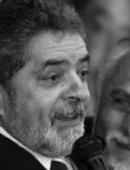

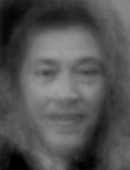

In [8]:
# filter the DataFrame by our label
awesome_df = train_df[train_df["label"] == LFWUtils.L2I["lula"]]

# index of image with our label
img_idx = 0
awesome_idx = awesome_df.index[img_idx]

# reconstruct image
pca_pixels = face_pca.inverse_transform(awesome_df.iloc[[img_idx]].drop(columns=["label"]))

display(make_image(train["pixels"][awesome_idx], width=LFWUtils.IMAGE_WIDTH))
display(make_image(pca_pixels, width=LFWUtils.IMAGE_WIDTH))

### Interpretation

<span style="color:hotpink;">
Do these make sense ? Do they look "recognizable" ? How do they change as a function of `PCA` <code>n_components</code> ?
</span>

The reconstructed images make sense as faces. They have the right overall shape, head position, eyes, nose and mouth in the right places, and the lighting direction. But they are much blurrier than the originals and look like a generic, averaged face, so they are only somewhat recognizable. With about 31 components (80% of the variance) PCA keeps the large shapes that most faces share, but it loses fine details like texture and the small features that make one person look different from another. As we increase n_components, more variance is kept and the reconstruction gets sharper and closer to the original, up to the point where it looks almost identical. With fewer components the images get blurrier and more alike until every face looks like the same average face.

Now, back to classifying...

Maybe start with `RandomForestClassifier()` or `SVC()`...

In [9]:
# TODO: create a classifier
classifier = RandomForestClassifier(random_state=42)

# TODO: separate input and output columns from the train DataFrame
train_inputs = train_df.drop(columns=["label"])
train_outputs = train_df["label"]

# TODO: train model using train data and labels
classifier.fit(train_inputs, train_outputs)

# TODO: run prediction on train data
train_predictions = classifier.predict(train_inputs)
print("First ten predictions:", train_predictions[:10])
print("First ten true labels:", list(train_outputs[:10]))

number_correct = (train_predictions == train_outputs).sum()
total_images = len(train_outputs)
train_accuracy = number_correct / total_images
print("Training accuracy:", train_accuracy)

First ten predictions: [0 0 0 0 0 0 0 0 0 0]
First ten true labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Training accuracy: 1.0


### Validate model with training data

error: 0.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00        22
           2       1.00      1.00      1.00        17
           3       1.00      1.00      1.00        24
           4       1.00      1.00      1.00        24
           5       1.00      1.00      1.00        19
           6       1.00      1.00      1.00        24
           7       1.00      1.00      1.00        14
           8       1.00      1.00      1.00        15
           9       1.00      1.00      1.00        16
          10       1.00      1.00      1.00        13
          11       1.00      1.00      1.00        10
          12       1.00      1.00      1.00        24
          13       1.00      1.00      1.00        11
          14       1.00      1.00      1.00        24
          15       1.00      1.00      1.00        11
          16       1.00      1.00      1.00        11
          17    

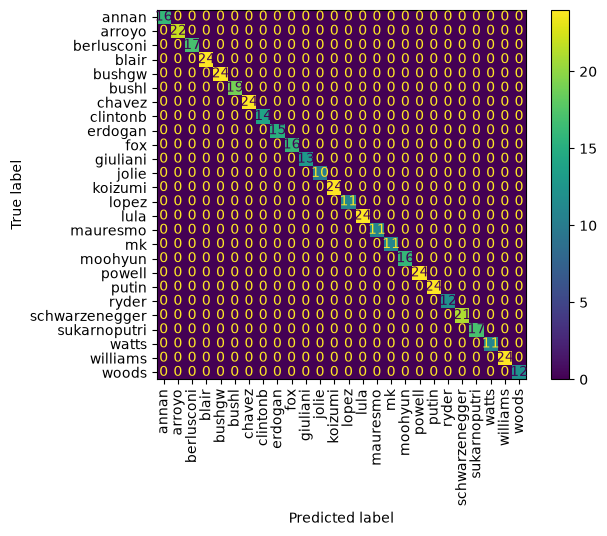

In [10]:
# measure classification error
print("error:", classification_error(train["labels"], train_predictions))

# look at precision/recall from classification_report
print(classification_report(train["labels"], train_predictions))

# look at confusion matrix
display_confusion_matrix(train["labels"], train_predictions, LFWUtils.LABELS)

### Interpretation

<span style="color:hotpink;">
How does the confusion matrix look ? What does it mean ?
</span>

The confusion matrix is a perfect diagonal. Every bright square sits where the true label and the predicted label are the same person and all the other squares are zero. This means the model classified every training image correctly, so the accuracy is 1.0 and the error is 0.0. However, this is measured on the same images the model learned from so it only shows that the model memorized the training set. It doesn't tell us how well it recognizes faces it hasn't seen. The real test is the test set where I expect some mistakes, so the matrix should have some off-diagonal squares, especially between people who look alike or who have few training images.

### Validate model with testing data

error: 0.6741071428571428
              precision    recall  f1-score   support

           0       0.38      0.40      0.39        15
           1       0.59      0.59      0.59        22
           2       0.00      0.00      0.00        16
           3       0.12      0.21      0.16        24
           4       0.22      0.33      0.26        24
           5       0.59      0.53      0.56        19
           6       0.06      0.08      0.07        24
           7       0.29      0.14      0.19        14
           8       0.20      0.14      0.17        14
           9       0.11      0.06      0.08        16
          10       0.12      0.08      0.10        13
          11       0.25      0.10      0.14        10
          12       0.45      0.62      0.53        24
          13       0.67      0.20      0.31        10
          14       0.38      0.33      0.36        24
          15       0.17      0.10      0.12        10
          16       0.75      0.90      0.82        10
 

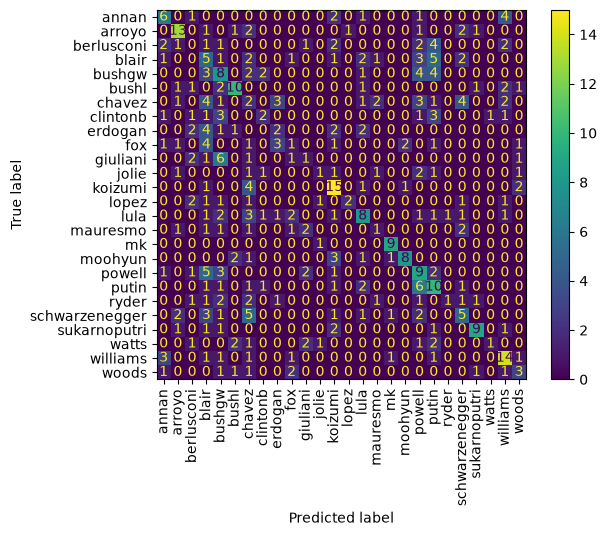

In [11]:
# TODO: run prediction on test data
test_inputs = test_df.drop(columns=["label"])
test_predictions = classifier.predict(test_inputs)

# TODO: measure classification error
test_error = classification_error(test["labels"], test_predictions)
print("error:", test_error)

# TODO: look at precision/recall from classification_report
test_report = classification_report(test["labels"], test_predictions)
print(test_report)

# TODO: look at confusion matrix
display_confusion_matrix(test["labels"], test_predictions, LFWUtils.LABELS)

### Different Classifiers

Try changing the classifier type above, or some of its parameters, to see if the overall accuracy can be improved.

Some things to try:
- `SVC(kernel="linear")`: this changes the type of curve the model tries to use to separate our classes. The more complex default type (`rbf`) might be over-fitting the data. We can experiment with `linear` or `poly` curves.
- `LogisticRegression()`: the classification that fits statistical modeling functions (bell curves) to our data.


### Hyper-parameter Optimization

Each model type has a handful of parameters that can be adjusted and optimized.

For example, we could add "regularization" to a `LogisticRegression` classifier with `C=0.1`.

Regularization is a process that makes training harder by setting more restrictions on the kind of answers it can give.

This can be restrictions like:
- keep all calculated parameters close to $0$
- minimize the number of non-zero parameters used
- keep all parameters positive

The result is slightly worse performance on the training dataset, but hopefully better generalization of the model and better performance on the test dataset.

In [12]:
# TODO: try LogisticRegression() and/or SVC(kernel="linear")
train_inputs = train_df.drop(columns=["label"])
train_outputs = train_df["label"]
test_inputs = test_df.drop(columns=["label"])
test_outputs = test["labels"]

scaler = StandardScaler()
train_inputs_scaled = scaler.fit_transform(train_inputs)
test_inputs_scaled = scaler.transform(test_inputs)

models_to_try = {
    "LogisticRegression C=0.1": LogisticRegression(C=0.1, max_iter=2000),
    "LogisticRegression C=1": LogisticRegression(C=1.0, max_iter=2000),
    "SVC linear": SVC(kernel="linear"),
    "SVC poly": SVC(kernel="poly"),
}

for model_name in models_to_try:
    model = models_to_try[model_name]
    model.fit(train_inputs_scaled, train_outputs)

    train_predictions_new = model.predict(train_inputs_scaled)
    test_predictions_new = model.predict(test_inputs_scaled)

    train_accuracy_new = (train_predictions_new == train_outputs).mean()
    test_accuracy_new = (test_predictions_new == test_outputs).mean()

    print(model_name)
    print("  train accuracy:", train_accuracy_new)
    print("  test accuracy: ", test_accuracy_new)

# TODO: does adding features (increasing PCA components) help ?
for variance_target in [0.8, 0.9, 0.95]:
    pca_try = PCA(n_components=variance_target)
    train_features_try = pca_try.fit_transform(train["pixels"])
    test_features_try = pca_try.transform(test["pixels"])

    scaler_try = StandardScaler()
    train_scaled_try = scaler_try.fit_transform(train_features_try)
    test_scaled_try = scaler_try.transform(test_features_try)

    model_try = LogisticRegression(C=0.1, max_iter=2000)
    model_try.fit(train_scaled_try, train["labels"])

    test_predictions_try = model_try.predict(test_scaled_try)
    test_accuracy_try = (test_predictions_try == test["labels"]).mean()

    print("variance target:", variance_target)
    print("  components:", pca_try.n_components_)
    print("  test accuracy:", test_accuracy_try)

LogisticRegression C=0.1
  train accuracy: 0.7521929824561403
  test accuracy:  0.42857142857142855
LogisticRegression C=1
  train accuracy: 0.8596491228070176
  test accuracy:  0.42410714285714285
SVC linear
  train accuracy: 0.993421052631579
  test accuracy:  0.4017857142857143
SVC poly
  train accuracy: 0.7171052631578947
  test accuracy:  0.18080357142857142
variance target: 0.8
  components: 30
  test accuracy: 0.42857142857142855
variance target: 0.9
  components: 76
  test accuracy: 0.5558035714285714
variance target: 0.95
  components: 144
  test accuracy: 0.6316964285714286


              precision    recall  f1-score   support

           0       0.71      0.67      0.69        15
           1       0.71      0.77      0.74        22
           2       0.29      0.25      0.27        16
           3       0.50      0.42      0.45        24
           4       0.50      0.54      0.52        24
           5       0.86      0.95      0.90        19
           6       0.57      0.71      0.63        24
           7       0.62      0.71      0.67        14
           8       0.88      0.50      0.64        14
           9       0.73      0.69      0.71        16
          10       0.45      0.38      0.42        13
          11       0.40      0.20      0.27        10
          12       0.86      0.79      0.83        24
          13       0.67      0.60      0.63        10
          14       0.68      0.71      0.69        24
          15       0.60      0.30      0.40        10
          16       1.00      0.60      0.75        10
          17       0.94    

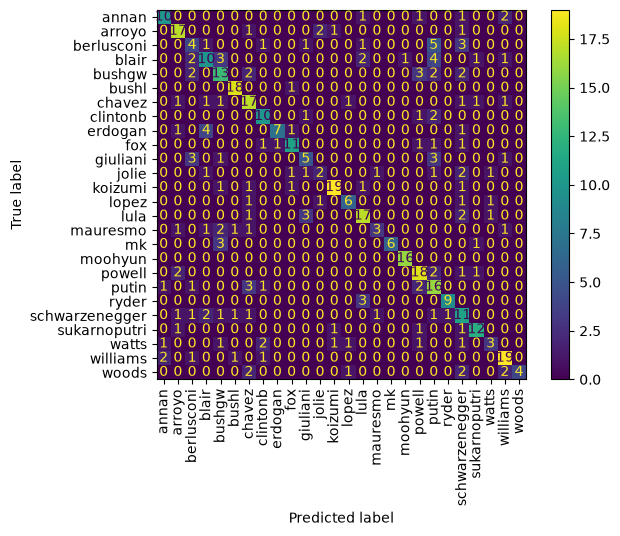

In [13]:
# confusion matrix for the best setup so far
best_pca = PCA(n_components=0.95)
best_train_features = best_pca.fit_transform(train["pixels"])
best_test_features = best_pca.transform(test["pixels"])

best_scaler = StandardScaler()
best_train_scaled = best_scaler.fit_transform(best_train_features)
best_test_scaled = best_scaler.transform(best_test_features)

best_model = LogisticRegression(C=0.1, max_iter=2000)
best_model.fit(best_train_scaled, train["labels"])
best_test_predictions = best_model.predict(best_test_scaled)

print(classification_report(test["labels"], best_test_predictions))
display_confusion_matrix(test["labels"], best_test_predictions, LFWUtils.LABELS)

### Interpretation

<span style="color:hotpink;">
How does THIS confusion matrix look ? What does it mean ? How does it perform for your pictures ?
</span>

The confusion matrix now has a clear diagonal, so most test images are labeled correctly (accuracy about 0.63, up from 0.34). It is still far from the perfect diagonal we got on the training data and there are scattered mistakes. Some people are recognized well (bushl, moohyun) and others poorly (berlusconi, jolie). This means the model learned something real about faces but it's not reliable enough for something like face unlock.

### Precision and Recall

Accuracy, which is the complement of our `classification_error` value, is the measurement that is optimized during the `RandomForestClassifier` training process.

If we were training a regular classifier, we would look at `accuracy` (or `classification_error`) to determine if our model's performance is acceptable.

Since we're working on a personal face recognition model, we don't really care about overall accuracy, but instead are more interested in the `precision` and `recall` values for the classification of our particular images.

We don't want overall accuracy to be horrible, but we can be more specific in this case and be happy if the correct portion of our confusion matrix looks good.

Calculate the `precision` and `recall` values for the classification of your images.

In [14]:
my_name = "mk"   # your one-word folder name, e.g. "tgh"
print("Is my name in the labels?", my_name in LFWUtils.LABELS)

my_label = LFWUtils.L2I[my_name]
true_labels = list(test["labels"])
predicted_labels = list(best_test_predictions)

true_positives = 0
false_positives = 0
false_negatives = 0

for position in range(len(true_labels)):
    actual = true_labels[position]
    predicted = predicted_labels[position]

    if predicted == my_label and actual == my_label:
        true_positives += 1
    if predicted == my_label and actual != my_label:
        false_positives += 1
    if predicted != my_label and actual == my_label:
        false_negatives += 1

# TODO: calculate precision
precision = true_positives / (true_positives + false_positives)
print("Precision:", precision)

# TODO: calculate recall
recall = true_positives / (true_positives + false_negatives)
print("Recall:", recall)

Is my name in the labels? True
Precision: 1.0
Recall: 0.6


### Interpretation

<span style="color:hotpink;">
How is it performing for your images ? Which value, precision or recall, is higher ? What does that mean ?
</span>

The model performs fairly well on my images. Precision is 1.0 and recall is 0.6, so precision is higher. Precision of 1.0 means that every time the model said an image was me, it was right and it never labeled someone else as me. Recall of 0.6 means it only found about 60% of my real photos and labeled the rest as other people. So the model is careful but misses me some of the time. For face unlock, that is the safer direction, since it won't let the wrong person in but I would sometimes have to try again. This is based on a small number of test photos so the numbers can change a lot.

We can run the following cell to see which classes have the highest `precision` and `recall` scores:

In [15]:
print("top precision:", LFWUtils.top_precision(test["labels"], test_predictions, top=5))
print("top recall:", LFWUtils.top_recall(test["labels"], test_predictions, top=5))

top precision: ['mk', 'moohyun', 'sukarnoputri', 'lopez', 'arroyo']
top recall: ['mk', 'koizumi', 'arroyo', 'williams', 'sukarnoputri']
